In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
import kagglehub

# Download do dataset
path = kagglehub.dataset_download("tarundalal/one-piece-arcs")

print("Caminho para o Dataset", path)

Using Colab cache for faster access to the 'one-piece-arcs' dataset.
Caminho para o Dataset /kaggle/input/one-piece-arcs


In [ ]:
import os

# O kagglehub salvou o caminho real na variável 'path' na célula anterior
caminho_pasta = path
print(os.listdir(caminho_pasta))

['OnePieceArcs.csv']


In [ ]:
import os

# Caminho corrigido usando a pasta onde o kagglehub baixou o dataset
dados = os.path.join(caminho_pasta, "OnePieceArcs.csv")

# Leitura
df = pd.read_csv(dados)

# Visualização inicial
df.head()

,Arc,Start onChapter,TotalChapters,TotalPages,Manga%,Start onEpisode,TotalEpisodes,TotalMinutes(avg 24),Anime%
0,Romance Dawn Arc,1,7,178,0.9%,1,3,72,0.3%
1,Orange Town Arc,8,14,273,1.4%,4,5,120,0.5%
2,Syrup Village Arc,22,20,396,2.0%,9,10,240,1.0%
3,Baratie Arc,42,27,514,2.6%,19,12,288,1.2%
4,Arlong Park Arc,69,27,514,2.6%,31,15,360,1.5%


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Arc                   51 non-null     object
 1   Start onChapter       51 non-null     int64 
 2   TotalChapters         51 non-null     int64 
 3   TotalPages            51 non-null     int64 
 4   Manga%                51 non-null     object
 5   Start onEpisode       51 non-null     int64 
 6   TotalEpisodes         51 non-null     int64 
 7   TotalMinutes(avg 24)  51 non-null     int64 
 8   Anime%                51 non-null     object
dtypes: int64(6), object(3)
memory usage: 3.7+ KB


In [ ]:
df.describe()

,Start onChapter,TotalChapters,TotalPages,Start onEpisode,TotalEpisodes,TotalMinutes(avg 24)
count,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000
mean,268.823529,20.705882,381.490196,354.745098,20.156863,483.764706
std,317.019287,26.133728,471.266268,291.209742,24.345326,584.287826
min,0.000000,0.000000,0.000000,1.000000,2.000000,48.000000
25%,0.000000,0.000000,0.000000,85.000000,4.000000,96.000000
50%,106.000000,11.000000,209.000000,313.000000,11.000000,264.000000
75%,519.500000,27.000000,514.000000,549.000000,30.000000,720.000000
max,958.000000,102.000000,1830.000000,959.000000,118.000000,2832.000000


In [ ]:
df.columns

Index(['Arc', 'Start onChapter', 'TotalChapters', 'TotalPages', 'Manga%',
       'Start onEpisode', 'TotalEpisodes', 'TotalMinutes(avg 24)', 'Anime%'],
      dtype='object')

In [ ]:
#Renomeando as colunas
df.rename(columns={
    'Arc': 'Arco',
    'Start onChapter': 'Capitulo_Inicio',
    'TotalChapters': 'Total_Capitulos',
    'TotalPages': 'Total_Paginas',
    'Start onEpisode': 'Episodio_Inicio',
    'TotalEpisodes': 'Total_Episodios',
    'TotalMinutes(avg 24)': 'Total_Minutos',
    'Anime%': 'Percentual_Anime'
}, inplace=True)

df.columns

Index(['Arco', 'Capitulo_Inicio', 'Total_Capitulos', 'Total_Paginas', 'Manga%',
       'Episodio_Inicio', 'Total_Episodios', 'Total_Minutos',
       'Percentual_Anime'],
      dtype='object')

# **Tratamento dos dados**

In [ ]:
#verificacão de nulos
print(df.isnull().sum())

Arco                0
Capitulo_Inicio     0
Total_Capitulos     0
Total_Paginas       0
Manga%              0
Episodio_Inicio     0
Total_Episodios     0
Total_Minutos       0
Percentual_Anime    0
dtype: int64


In [ ]:
#que tipo de dados são?
print(df.dtypes)

Arco                object
Capitulo_Inicio      int64
Total_Capitulos      int64
Total_Paginas        int64
Manga%              object
Episodio_Inicio      int64
Total_Episodios      int64
Total_Minutos        int64
Percentual_Anime    object
dtype: object


In [ ]:
#Convertendo as colunas Manga e percentual anime que estão com % para dados tipo float
for col in ['Manga%', 'Percentual_Anime']:
    if df[col].dtype == 'object':  # se for string
        df[col] = df[col].str.rstrip('%').astype(float)


In [ ]:
print(df.dtypes)

Arco                 object
Capitulo_Inicio       int64
Total_Capitulos       int64
Total_Paginas         int64
Manga%              float64
Episodio_Inicio       int64
Total_Episodios       int64
Total_Minutos         int64
Percentual_Anime    float64
dtype: object


In [ ]:
#verificação de como ficou no dataset
df.head()

,Arco,Capitulo_Inicio,Total_Capitulos,Total_Paginas,Manga%,Episodio_Inicio,Total_Episodios,Total_Minutos,Percentual_Anime
0,Romance Dawn Arc,1,7,178,0.9,1,3,72,0.3
1,Orange Town Arc,8,14,273,1.4,4,5,120,0.5
2,Syrup Village Arc,22,20,396,2.0,9,10,240,1.0
3,Baratie Arc,42,27,514,2.6,19,12,288,1.2
4,Arlong Park Arc,69,27,514,2.6,31,15,360,1.5


In [ ]:
#Verficação de valores duplicados
print(df.duplicated().sum())


0


In [ ]:
#vericação se os nomes estão certos e não escritos 2x de formas diferentes
print(df['Arco'].nunique())
print(df['Arco'].unique())

51
['Romance Dawn Arc' 'Orange Town Arc' 'Syrup Village Arc' 'Baratie Arc'
 'Arlong Park Arc' 'Buggy Side Story Arc' 'Loguetown Arc'
 'Warship Island Arc' 'Reverse Mountain Arc' 'Whiskey Peak Arc'
 'Koby and Helmeppo Arc' 'Little Garden Arc' 'Drum Island Arc'
 'Alabasta Arc' 'Post-Alabasta Arc' 'Goat Island Arc' 'Ruluka Island Arc'
 'Jaya Arc' 'Skypiea Arc' 'G-8 Arc' 'Long Ring Long Land Arc'
 "Ocean's Dream Arc" "Foxy's Return Arc" 'Water 7 Arc' 'Enies Lobby Arc'
 'Post-Enies Lobby Arc' 'Ice Hunter Arc' 'Thriller Bark Arc'
 'Spa Island Arc' 'Sabaody Archipelago Arc' 'Special Historical Arc'
 'Amazon Lily Arc' 'Impel Down Arc' 'Little East Blue Arc'
 'Marineford Arc' 'Post-War Arc' 'Return to Sabaody Arc'
 'Fishman Island Arc' "Z's Ambition Arc" 'Punk Hazard Arc'
 'Caesar Retrieval Arc' 'Dressrosa Arc' 'Silver Mine Arc' 'Zou Arc'
 'Marine Rookie Arc' 'Whole Cake Island Arc' 'Levely Arc'
 'Wano Country Arc: Act 1' 'Cidre Guild Arc' 'Wano Country Arc: Act 2'
 'Wano Country Arc: Act 3']


# Verificação de Ouliers

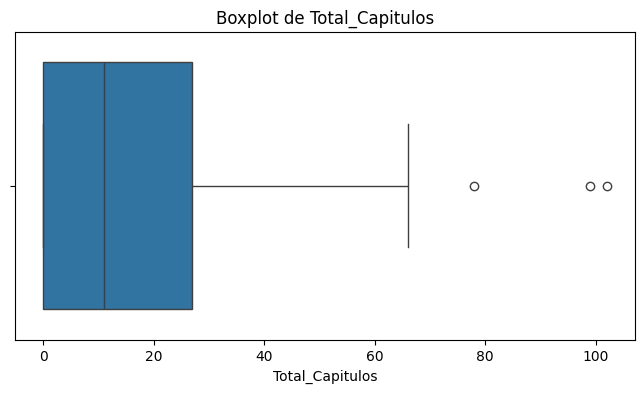

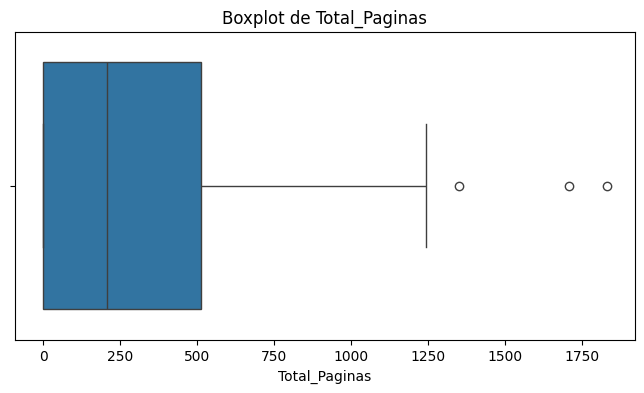

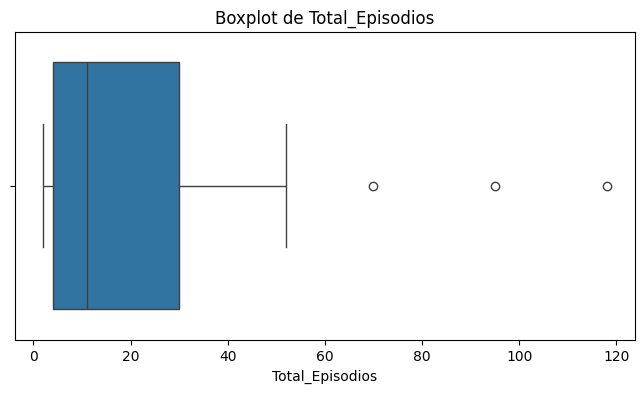

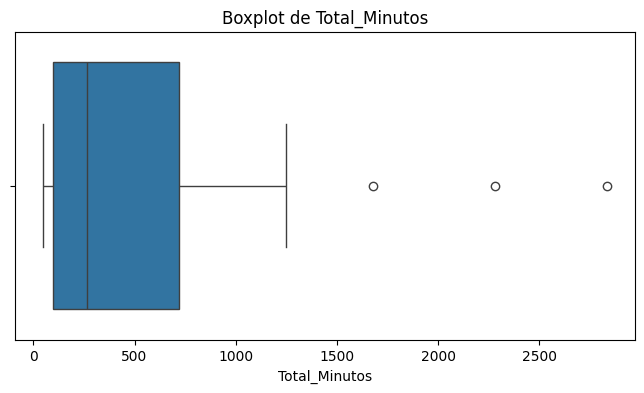

In [ ]:
outliers = ['Total_Capitulos', 'Total_Paginas', 'Total_Episodios', 'Total_Minutos']

for col in outliers:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot de {col}')
    plt.show()


Observa-se um padrao nos ouliers, para decidir se mantém ou retira eles, vamos descobrir quem são esses outliers porque sabe-se que alguns arcos tem mais episódios e páginas que outros


In [ ]:
# Calcular quartis e IQR
Q1 = df['Total_Paginas'].quantile(0.25)
Q3 = df['Total_Paginas'].quantile(0.75)
IQR = Q3 - Q1

# Filtrar linhas que são outliers
outliers = df[(df['Total_Paginas'] < Q1 - 1.5 * IQR) | (df['Total_Paginas'] > Q3 + 1.5 * IQR)]

# Mostrar os arcos e os valores dessas linhas
print(outliers[['Arco', 'Total_Paginas']])

                       Arco  Total_Paginas
41            Dressrosa Arc           1830
45    Whole Cake Island Arc           1349
50  Wano Country Arc: Act 3           1709


Assim descobrimos que os maiores arcos em número de páginas do mangá são Whole Cake Island, Wano terceiro ato e Dressrosa respectivamente.

In [ ]:
# Calcular quartis e IQR
Q1 = df['Total_Episodios'].quantile(0.25)
Q3 = df['Total_Episodios'].quantile(0.75)
IQR = Q3 - Q1

# Filtrar linhas que são outliers
outliers = df[(df['Total_Episodios'] < Q1 - 1.5 * IQR) | (df['Total_Episodios'] > Q3 + 1.5 * IQR)]

# Mostrar os arcos e os valores dessas linhas
print(outliers[['Arco', 'Total_Episodios']])

                       Arco  Total_Episodios
41            Dressrosa Arc              118
45    Whole Cake Island Arc               95
50  Wano Country Arc: Act 3               70


# Conclusão

No conjunto de dados, Dressrosa aparece como o arco com maior número de páginas e episódios, destacando-se como o mais extenso tanto no mangá quanto na adaptação em anime. Já o arco Wano, embora tenha mais páginas no mangá do que Whole Cake Island, apresenta menos episódios no anime. Isso indica que, na adaptação para vídeo, a ordem de duração muda: Wano é mais longo no mangá, mas é animado com menos episódios do que Whole Cake Island.

Isso sugere que a adaptação do arco Dressrosa manteve muitos detalhes, refletidos em sua alta quantidade de episódios, enquanto Wano, apesar de ter mais conteúdo no mangá, foi adaptado de forma mais condensada, talvez resumindo partes para caber em menos episódios do que Whole Cake Island.